# Assignment 1 — Exploratory Data Analysis and Preprocessing

**Purpose:** Analyse the validated data and create leakage-safe model inputs for both architectures.

This notebook is an executable evidence view over the shared local pipeline. The
command-line runner and notebook call the same stage implementation, preventing code
drift. Completed artifacts are reused; no Google Colab or Google Drive runtime is used.


In [1]:
# Local WSL project bootstrap. Dependency installation belongs to the
# locked project environment and is intentionally not repeated in notebooks.
from pathlib import Path
import json
import os
import platform
import sys

candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [candidate, *candidate.parents] if (path / "shared").exists()),
    candidate,
)
if not (PROJECT_ROOT / "shared").exists():
    raise FileNotFoundError(
        "Open this notebook from the local odl-assignment project root."
    )
os.environ["ODL_PROJECT_ROOT"] = str(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared.config import PATHS
from shared.runtime import RuntimeOptions
from shared.workflow import run_stage

OPTIONS = RuntimeOptions.from_environment()
print("Project root:", PROJECT_ROOT)
print("Run mode:", OPTIONS.mode)
print("Device policy:", OPTIONS.device)
print("WSL distribution:", os.getenv("WSL_DISTRO_NAME", "not detected"))


I0000 00:00:1786469159.594263    6432 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786469159.646889    6432 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Project root: /home/nicholas/code/odl-assignment
Run mode: smoke
Device policy: gpu
WSL distribution: Ubuntu-24.04


I0000 00:00:1786469160.760047    6432 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Run the shared stage or load its verified completed result.
STAGE_SUMMARY = run_stage("prepare", options=OPTIONS)
STAGE_SUMMARY


{'rows': 420768,
 'features': 41,
 'split_counts': {'train': 291862, 'validation': 59962, 'test': 59917},
 'sequence_shape': [4, 24, 41],
 'target_shape': [4, 1],
 'run_mode': 'smoke'}

In [3]:
# Record the exact runtime used for this output when preflight evidence exists.
environment_path = PATHS.environment_artifacts / f"environment_{OPTIONS.mode}.json"
ENVIRONMENT = (
    json.loads(environment_path.read_text(encoding="utf-8"))
    if environment_path.exists()
    else {"status": "preflight evidence not yet generated"}
)
ENVIRONMENT


{'captured_at_utc': '2026-08-11T17:24:19.219395+00:00',
 'project_root': '/home/nicholas/code/odl-assignment',
 'platform': 'Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'system': 'Linux',
 'release': '6.6.87.2-microsoft-standard-WSL2',
 'python': '3.12.3',
 'wsl_distribution': 'Ubuntu-24.04',
 'device': 'gpu',
 'tensorflow_gpu_devices': ['/physical_device:GPU:0'],
 'batch_size': 256,
 'mixed_precision': False,
 'nvidia_smi': {'available': True,
  'name': 'NVIDIA GeForce RTX 3050 Laptop GPU',
  'driver_version': '591.74',
  'memory.total': '4096',
  'memory.used': '167',
  'utilization.gpu': '3',
  'temperature.gpu': '56',
  'power.draw': '17.34'},
 'packages': {'tensorflow': '2.21.0',
  'keras-tuner': '1.4.8',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'pyarrow': '25.0.0',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1',
  'seaborn': '0.13.2'},
 'git': {'available': True,
  'revision': '7b64970eb262a89eacb2684e5f337af7b67c5d4b',
  'dirty': True},
 'experiment_co

## Distribution, missingness, and station differences

These outputs quantify the target's skew, extreme values, spatial variation, and the
length of missing runs before causal imputation.


,count,mean,std,min,1%,25%,50%,75%,99%,max
PM2.5,412029.0,79.793428,80.822391,2.0000,3.0,20.0,55.0,111.0,370.0,999.0
PM10,414319.0,104.602618,91.772426,2.0000,5.0,36.0,82.0,145.0,422.0,999.0
SO2,411747.0,15.830835,21.650603,0.2856,2.0,3.0,7.0,20.0,104.0,500.0
NO2,408652.0,50.638586,35.127912,1.0265,2.0,23.0,43.0,71.0,157.0,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,100.0,500.0,900.0,1500.0,6000.0,10000.0
O3,407491.0,57.372271,56.661607,0.2142,1.0,11.0,45.0,82.0,245.0,1071.0
TEMP,420370.0,13.538976,11.436139,-19.9000,-7.9,3.1,14.5,23.3,33.8,41.6
PRES,420375.0,1010.746982,10.474055,982.4000,990.4,1002.3,1010.4,1019.0,1032.5,1042.8
DEWP,420365.0,2.490822,13.793847,-43.4000,-24.8,-8.9,3.1,15.1,24.5,29.1
RAIN,420378.0,0.064476,0.821004,0.0000,0.0,0.0,0.0,0.0,1.4,72.5


,station,column,missing_runs,maximum_run_hours,median_run_hours
40,Dongsi,CO,304,1517,1.0
28,Dingling,CO,330,1051,1.0
39,Dongsi,NO2,204,900,1.0
100,Shunyi,CO,723,749,1.0
124,Wanliu,CO,320,642,1.0
123,Wanliu,NO2,305,548,1.0
101,Shunyi,O3,492,497,1.0
110,Tiantan,SO2,303,457,1.0
52,Guanyuan,CO,345,441,1.0
125,Wanliu,O3,783,429,1.0


,station,count,mean,median,std,min,max
0,Aotizhongxin,34139,82.773611,58.0,82.135694,3.0,898.0
1,Changping,34290,71.099743,46.0,72.326926,2.0,882.0
2,Dingling,34285,65.989497,41.0,72.267723,3.0,881.0
3,Dongsi,34314,86.194297,61.0,86.575127,3.0,737.0
4,Guanyuan,34448,82.933372,59.0,80.933497,2.0,680.0
5,Gucheng,34418,83.852089,60.0,82.796445,2.0,770.0
6,Huairou,34111,69.626367,47.0,71.224916,2.0,762.0
7,Nongzhanguan,34436,84.838483,59.0,86.225344,2.0,844.0
8,Shunyi,34151,79.491602,55.0,81.231739,2.0,941.0
9,Tiantan,34387,82.164911,59.0,80.921384,3.0,821.0


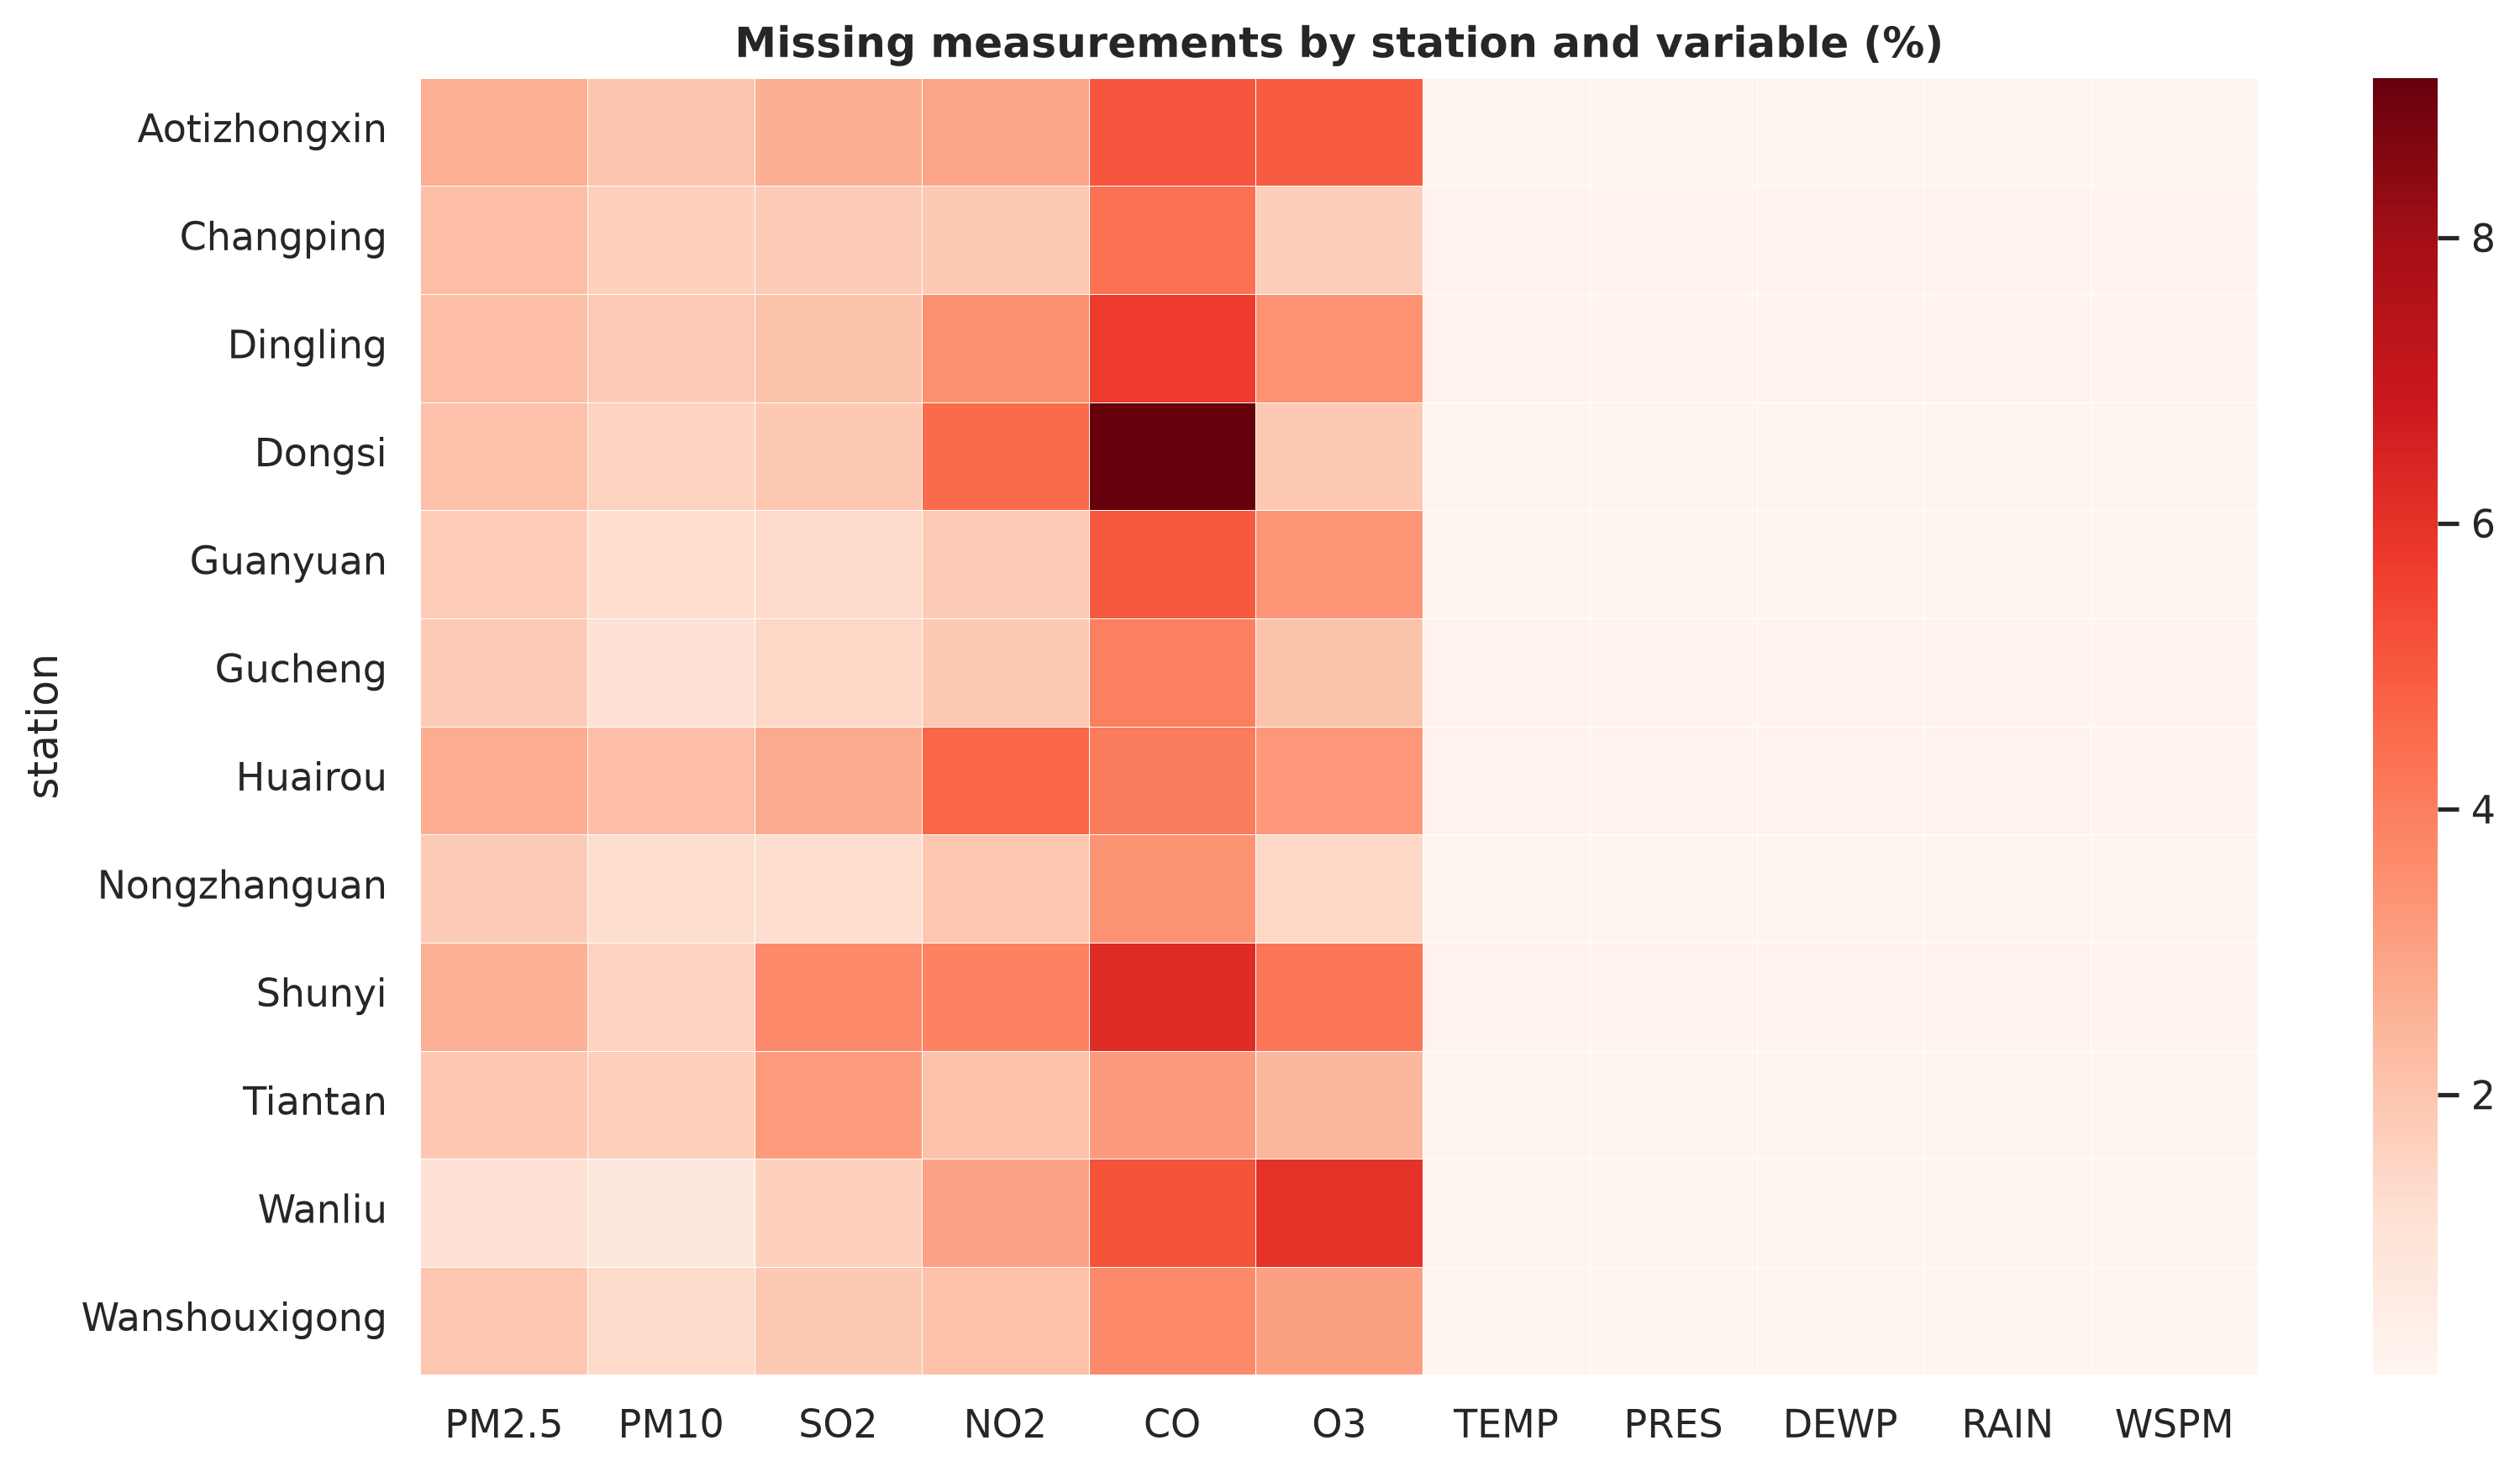

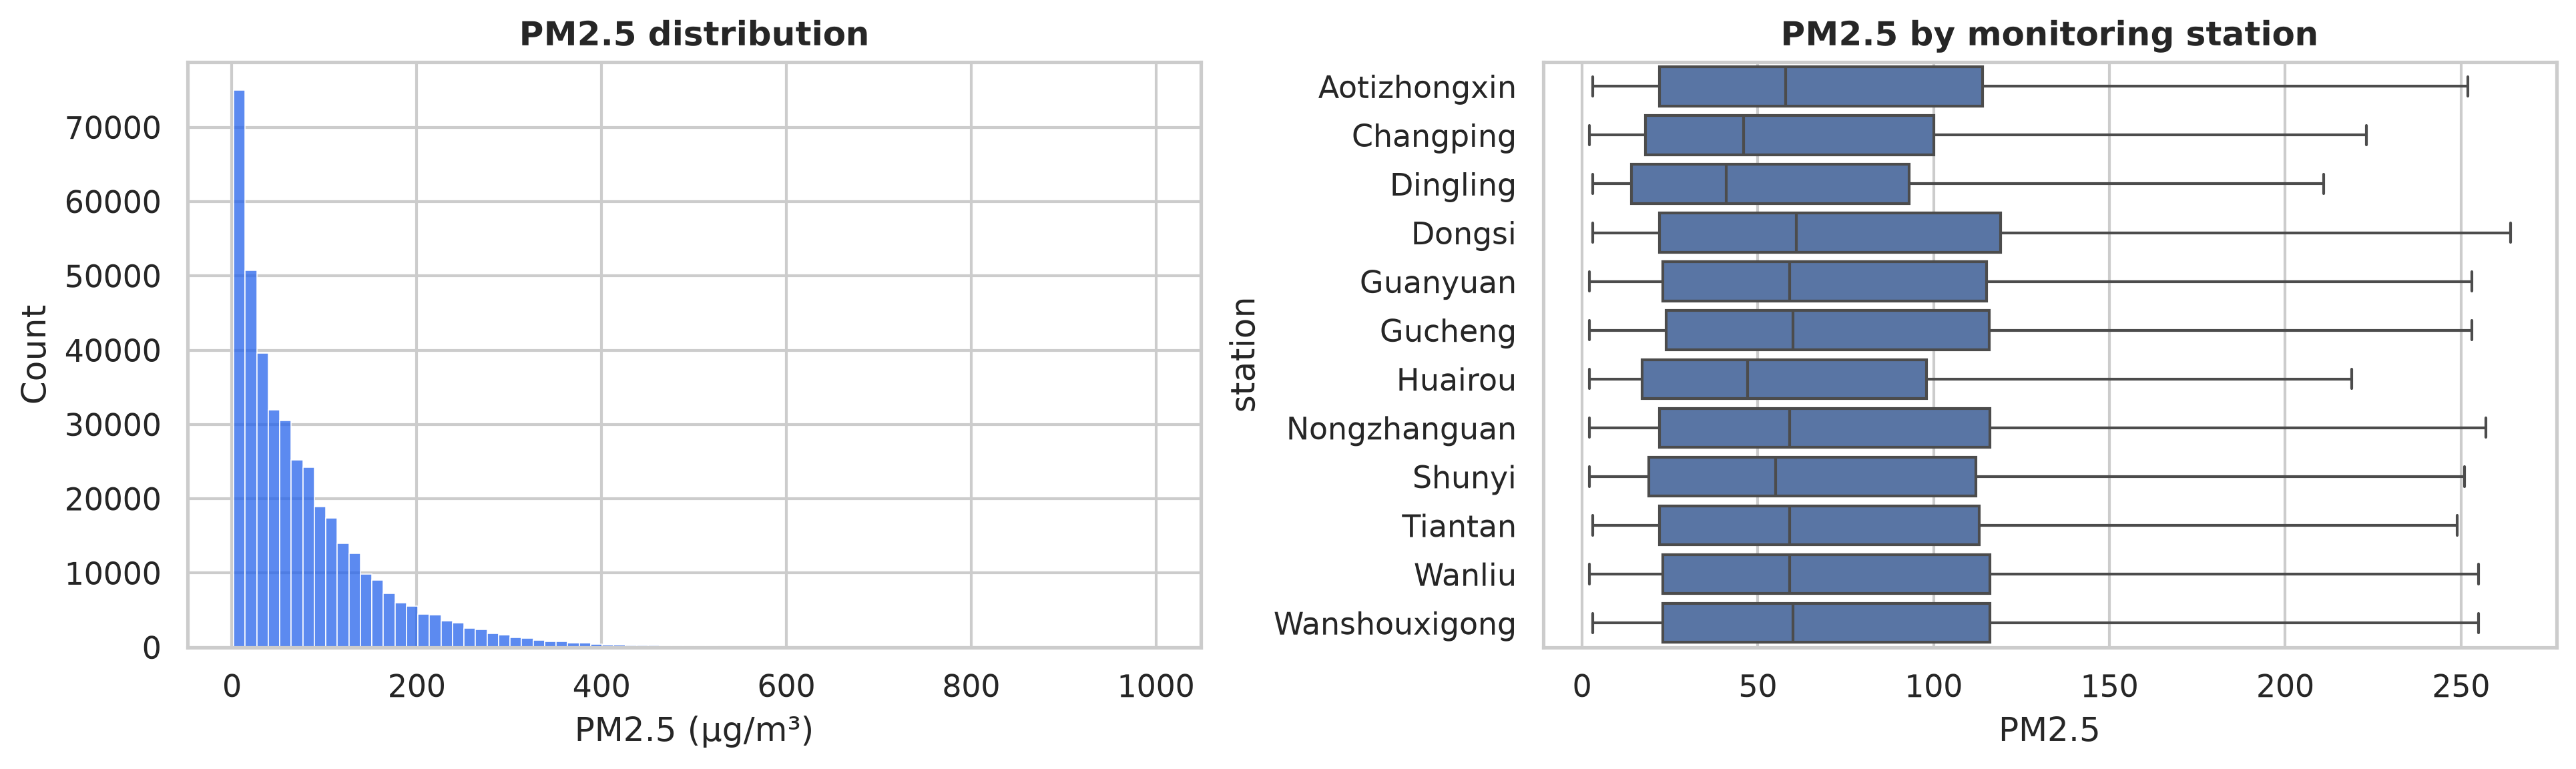

In [4]:
import pandas as pd
from IPython.display import Image, display

descriptive = pd.read_csv(
    PATHS.assignment1_tables / "descriptive_statistics.csv", index_col=0
)
missing_runs = pd.read_csv(PATHS.assignment1_tables / "missing_run_summary.csv")
station_statistics = pd.read_csv(
    PATHS.assignment1_tables / "pm25_station_statistics.csv"
)
display(descriptive)
display(missing_runs.sort_values("maximum_run_hours", ascending=False).head(20))
display(station_statistics)
display(Image(filename=str(PATHS.assignment1_figures / "missingness_heatmap.png")))
display(Image(filename=str(
    PATHS.assignment1_figures / "pm25_distribution_and_station_boxplots.png"
)))


## Temporal and feature relationships

Hourly/seasonal behaviour and autocorrelation justify cyclical features and the
24-hour sequence length. Correlation and sampled scatter plots provide complementary
evidence about contemporaneous predictors.


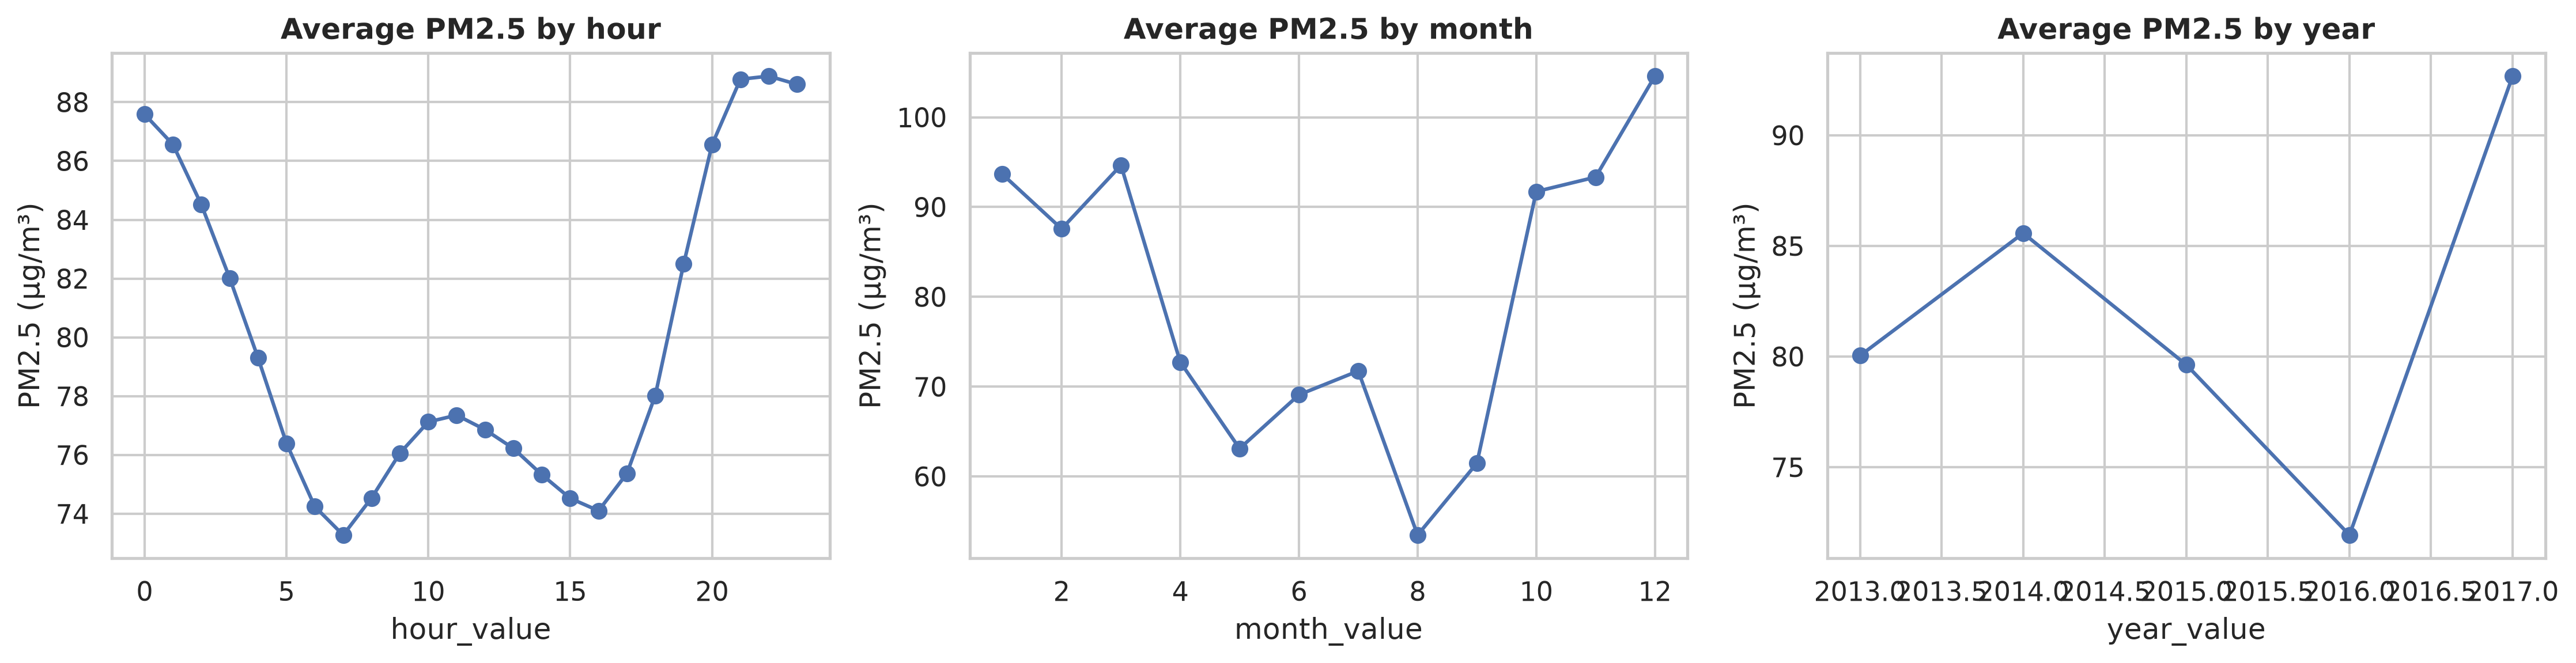

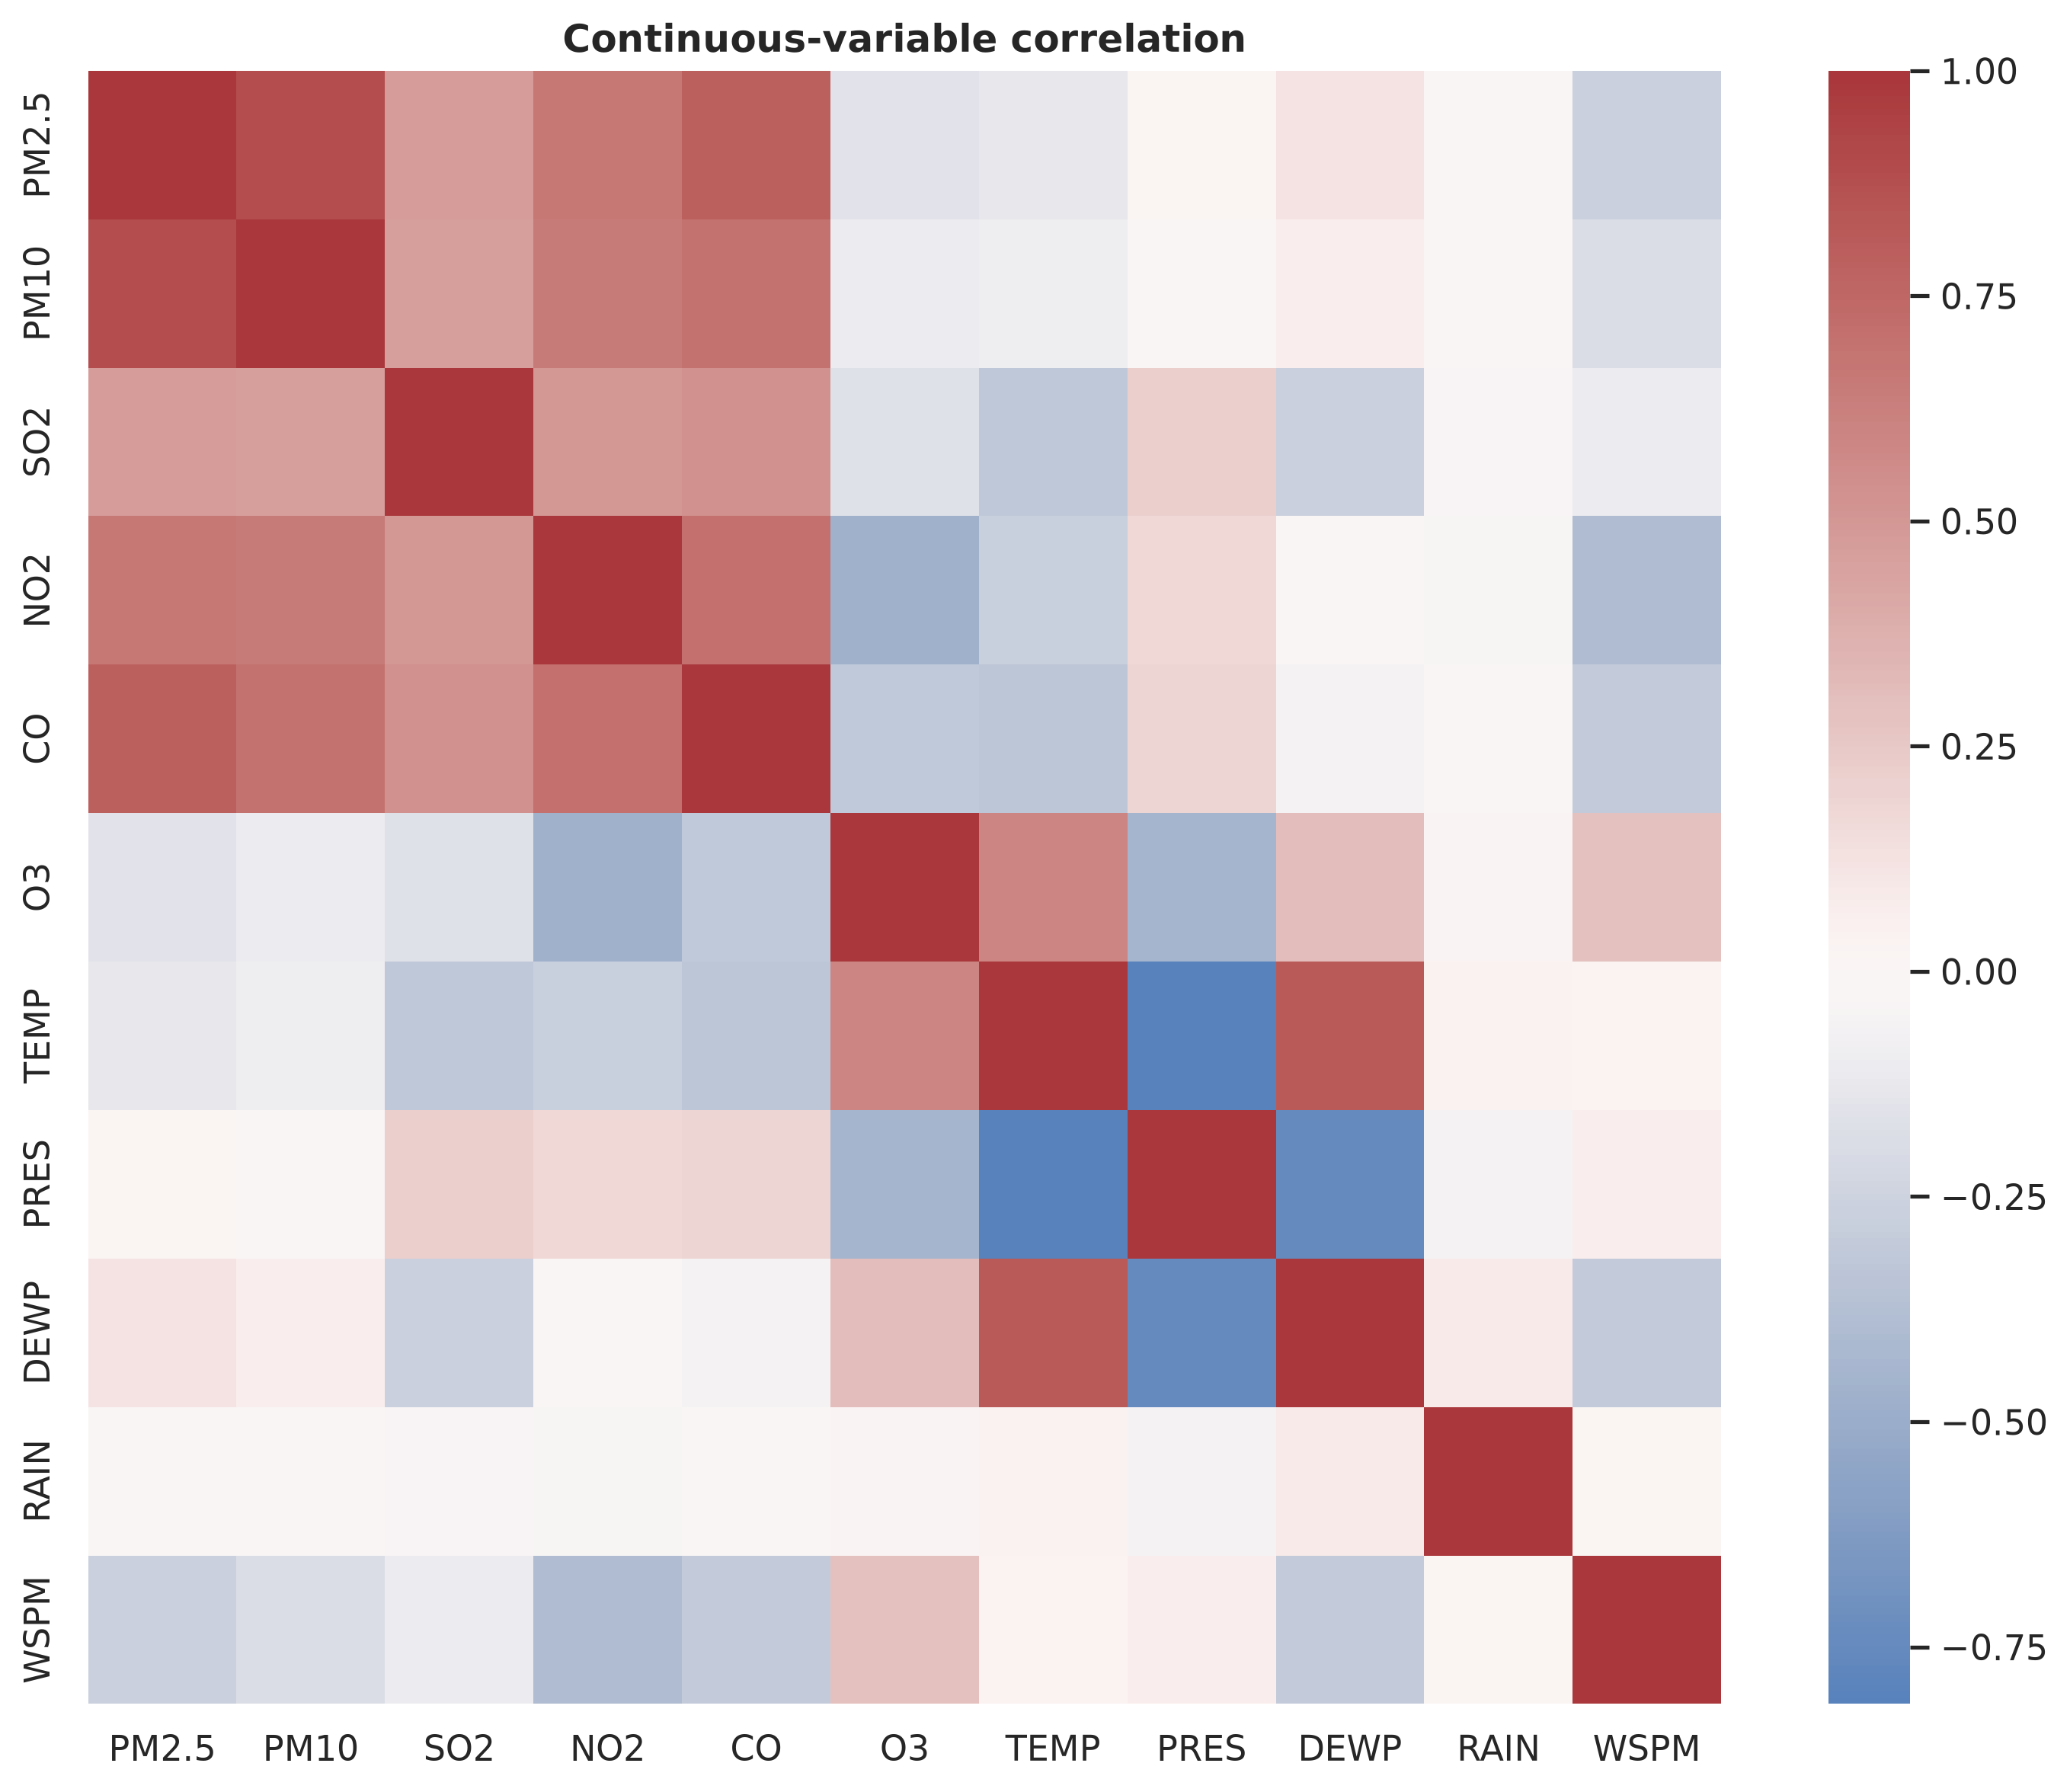

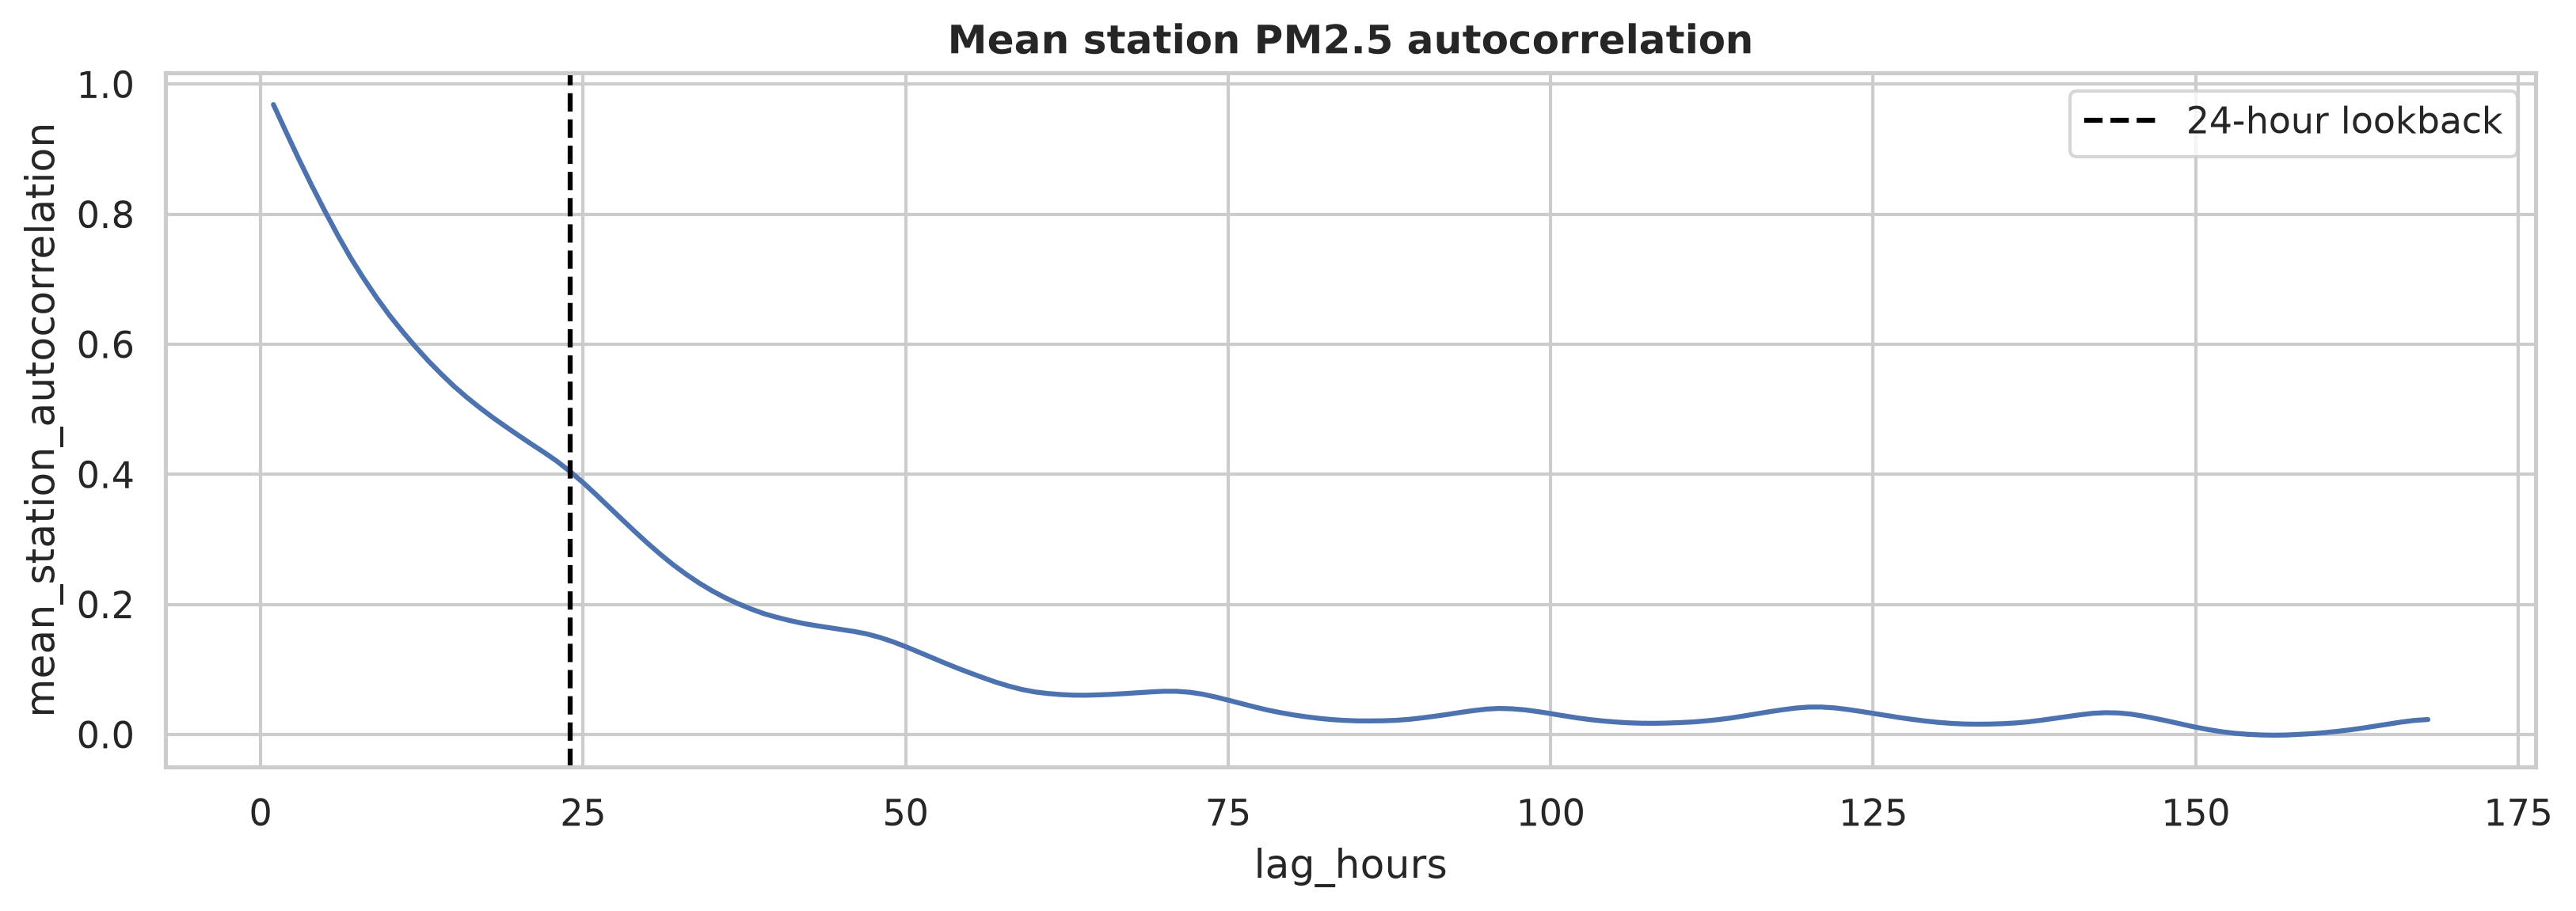

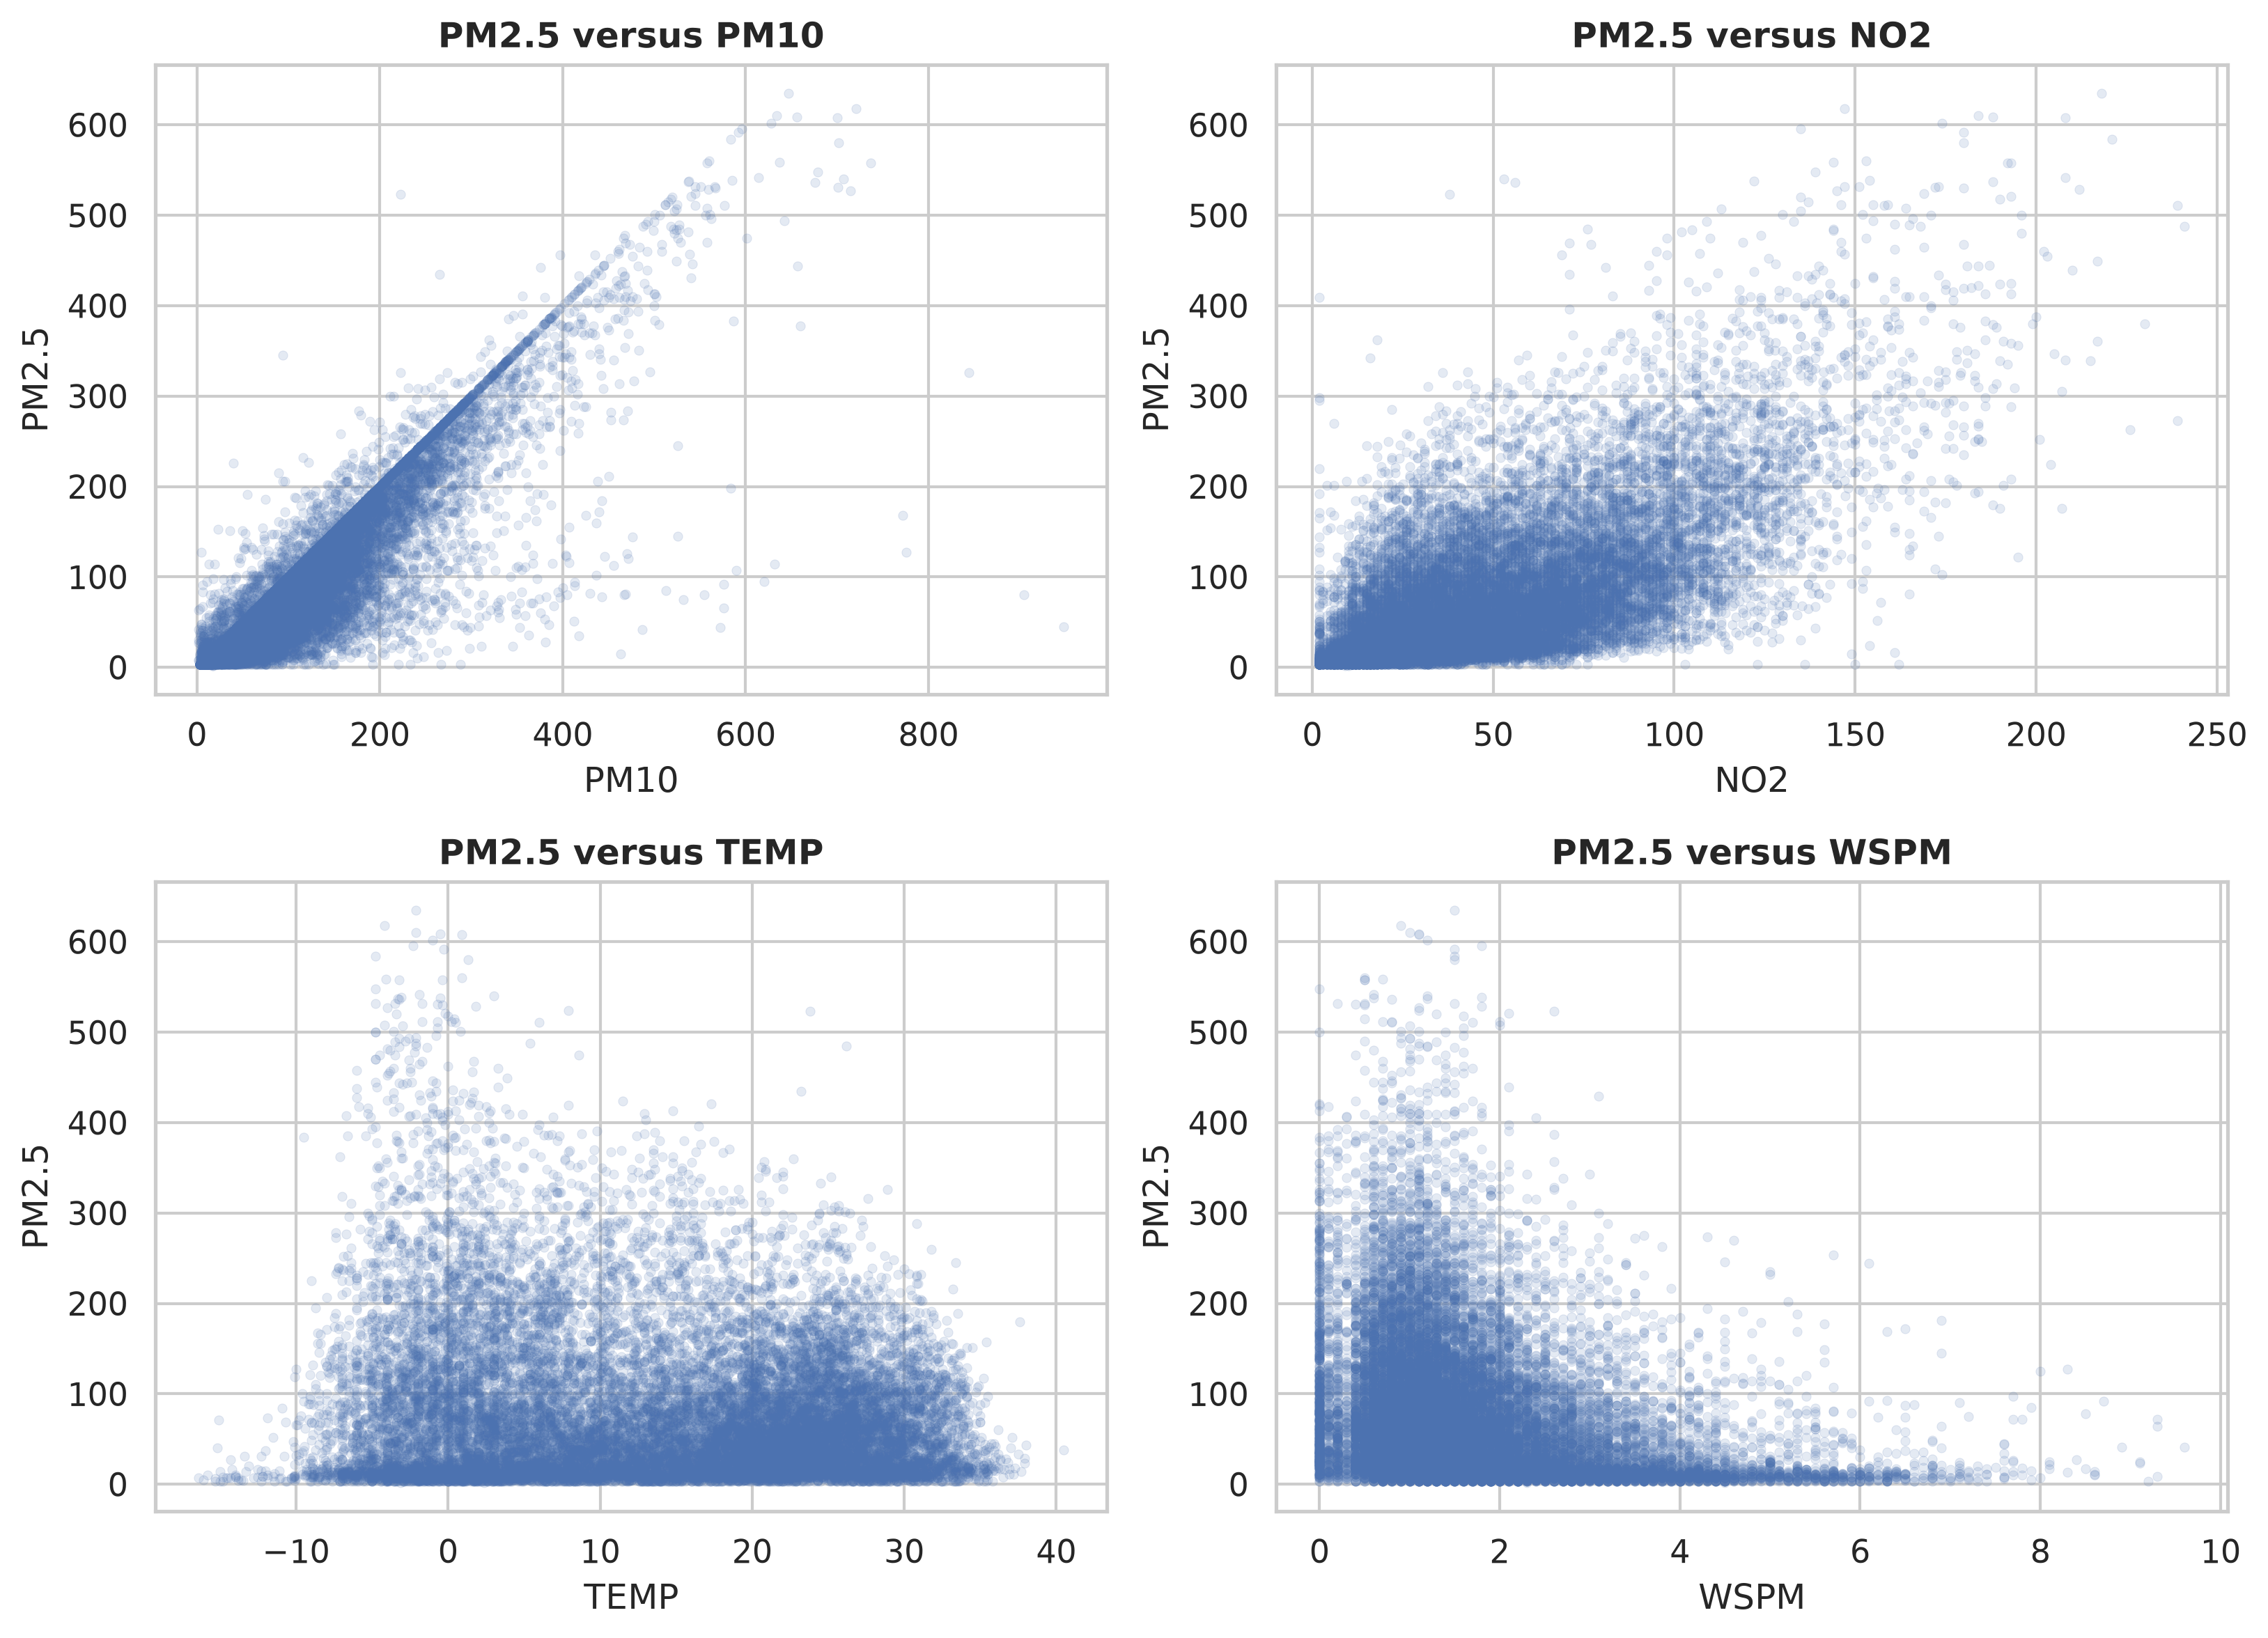

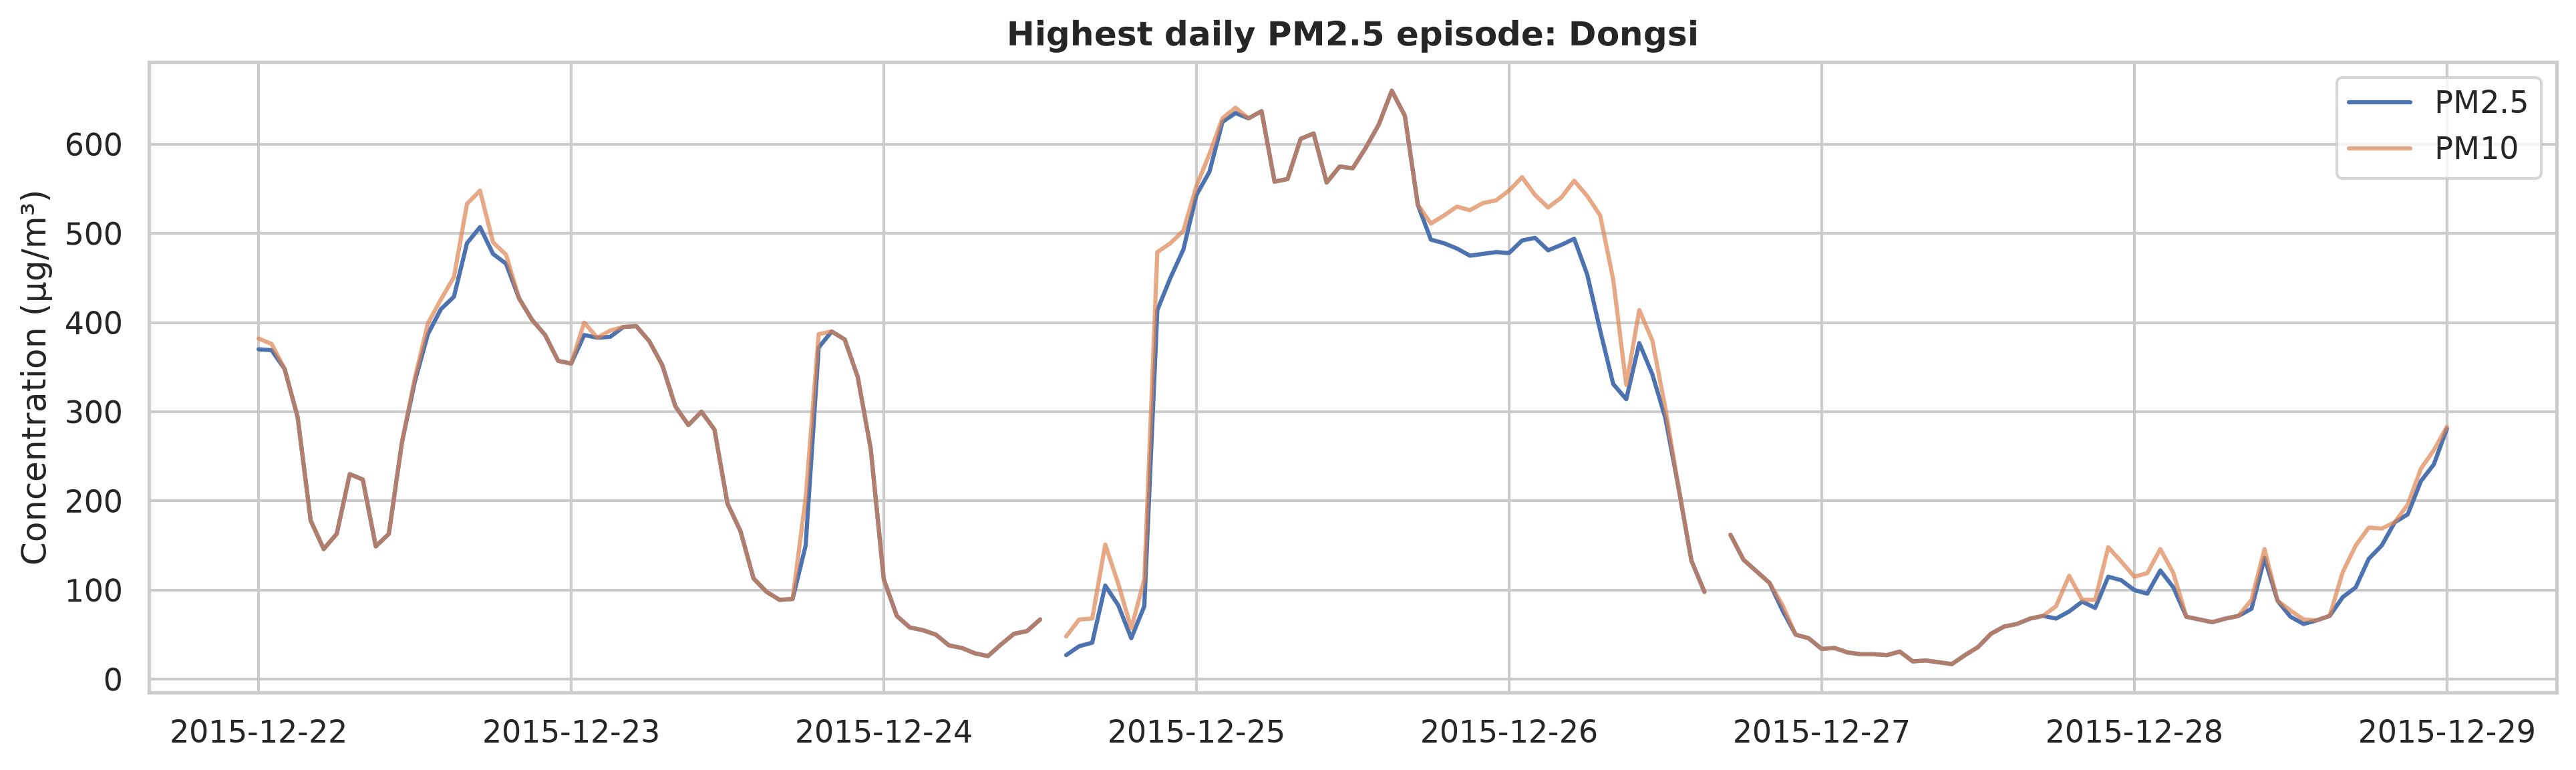

In [5]:
display(Image(filename=str(PATHS.assignment1_figures / "pm25_temporal_patterns.png")))
display(Image(filename=str(
    PATHS.assignment1_figures / "continuous_correlation_heatmap.png"
)))
display(Image(filename=str(PATHS.assignment1_figures / "pm25_autocorrelation.png")))
display(Image(filename=str(
    PATHS.assignment1_figures / "pm25_feature_relationships.png"
)))
display(Image(filename=str(
    PATHS.assignment1_figures / "selected_pollution_episode.png"
)))


## Leakage-safe preprocessing and chronological splits

**Decision.** Use capped causal forward filling, training-only station/global medians,
training-fitted scaling, and target-time chronological splits. **Alternatives.** Random
splitting leaks future regimes; unrestricted filling can freeze a sensor for weeks;
interpolation can use future values. **Evidence.** The missing-run table includes long
pollutant gaps, while the ablation tables select the fill cap and lookback over three
expanding validation folds. **Support.** Rolling evaluation respects forecasting order
([Bergmeir et al.](https://doi.org/10.1016/j.csda.2017.11.003)). **Trade-off.** Median
fallback is robust but smooths unusual conditions. Targets retain original, unfilled
measurements and splits are assigned by target timestamp.


{'features': ['z__PM2.5',
  'z__PM10',
  'z__SO2',
  'z__NO2',
  'z__CO',
  'z__O3',
  'z__TEMP',
  'z__PRES',
  'z__DEWP',
  'z__RAIN',
  'z__WSPM',
  'missing__PM2.5',
  'missing__PM10',
  'missing__SO2',
  'missing__NO2',
  'missing__CO',
  'missing__O3',
  'missing__TEMP',
  'missing__PRES',
  'missing__DEWP',
  'missing__RAIN',
  'missing__WSPM',
  'hour_sin',
  'hour_cos',
  'doy_sin',
  'doy_cos',
  'wind_sin',
  'wind_cos',
  'wind_missing',
  'station__Aotizhongxin',
  'station__Changping',
  'station__Dingling',
  'station__Dongsi',
  'station__Guanyuan',
  'station__Gucheng',
  'station__Huairou',
  'station__Nongzhanguan',
  'station__Shunyi',
  'station__Tiantan',
  'station__Wanliu',
  'station__Wanshouxigong'],
 'count': 41}

{'lookback_hours': 24,
 'forward_fill_limit_hours': 24,
 'forecast_horizon': 1,
 'feature_count': 41,
 'features': ['z__PM2.5',
  'z__PM10',
  'z__SO2',
  'z__NO2',
  'z__CO',
  'z__O3',
  'z__TEMP',
  'z__PRES',
  'z__DEWP',
  'z__RAIN',
  'z__WSPM',
  'missing__PM2.5',
  'missing__PM10',
  'missing__SO2',
  'missing__NO2',
  'missing__CO',
  'missing__O3',
  'missing__TEMP',
  'missing__PRES',
  'missing__DEWP',
  'missing__RAIN',
  'missing__WSPM',
  'hour_sin',
  'hour_cos',
  'doy_sin',
  'doy_cos',
  'wind_sin',
  'wind_cos',
  'wind_missing',
  'station__Aotizhongxin',
  'station__Changping',
  'station__Dingling',
  'station__Dongsi',
  'station__Guanyuan',
  'station__Gucheng',
  'station__Huairou',
  'station__Nongzhanguan',
  'station__Shunyi',
  'station__Tiantan',
  'station__Wanliu',
  'station__Wanshouxigong'],
 'split_counts': {'train': 58319, 'validation': 0, 'test': 10062},
 'split_boundaries': {'train_start': '2013-03-01 00:00:00',
  'validation_start': '2016-08-01 0

,count,mean,median,std,min,max
split,,,,,,
test,59917,85.328237,53.0,93.632098,2.0,835.0
train,291862,81.905645,58.0,80.172557,2.0,844.0
validation,59962,64.329725,45.0,67.255427,3.0,999.0


,fill_limit,mean_mae,std_mae,evaluations,se_mae,preference_rank
0,24,42.078313,NaN,1,0.0,0


,lookback,mean_mae,std_mae,evaluations,se_mae
0,24,42.078313,NaN,1,0.0


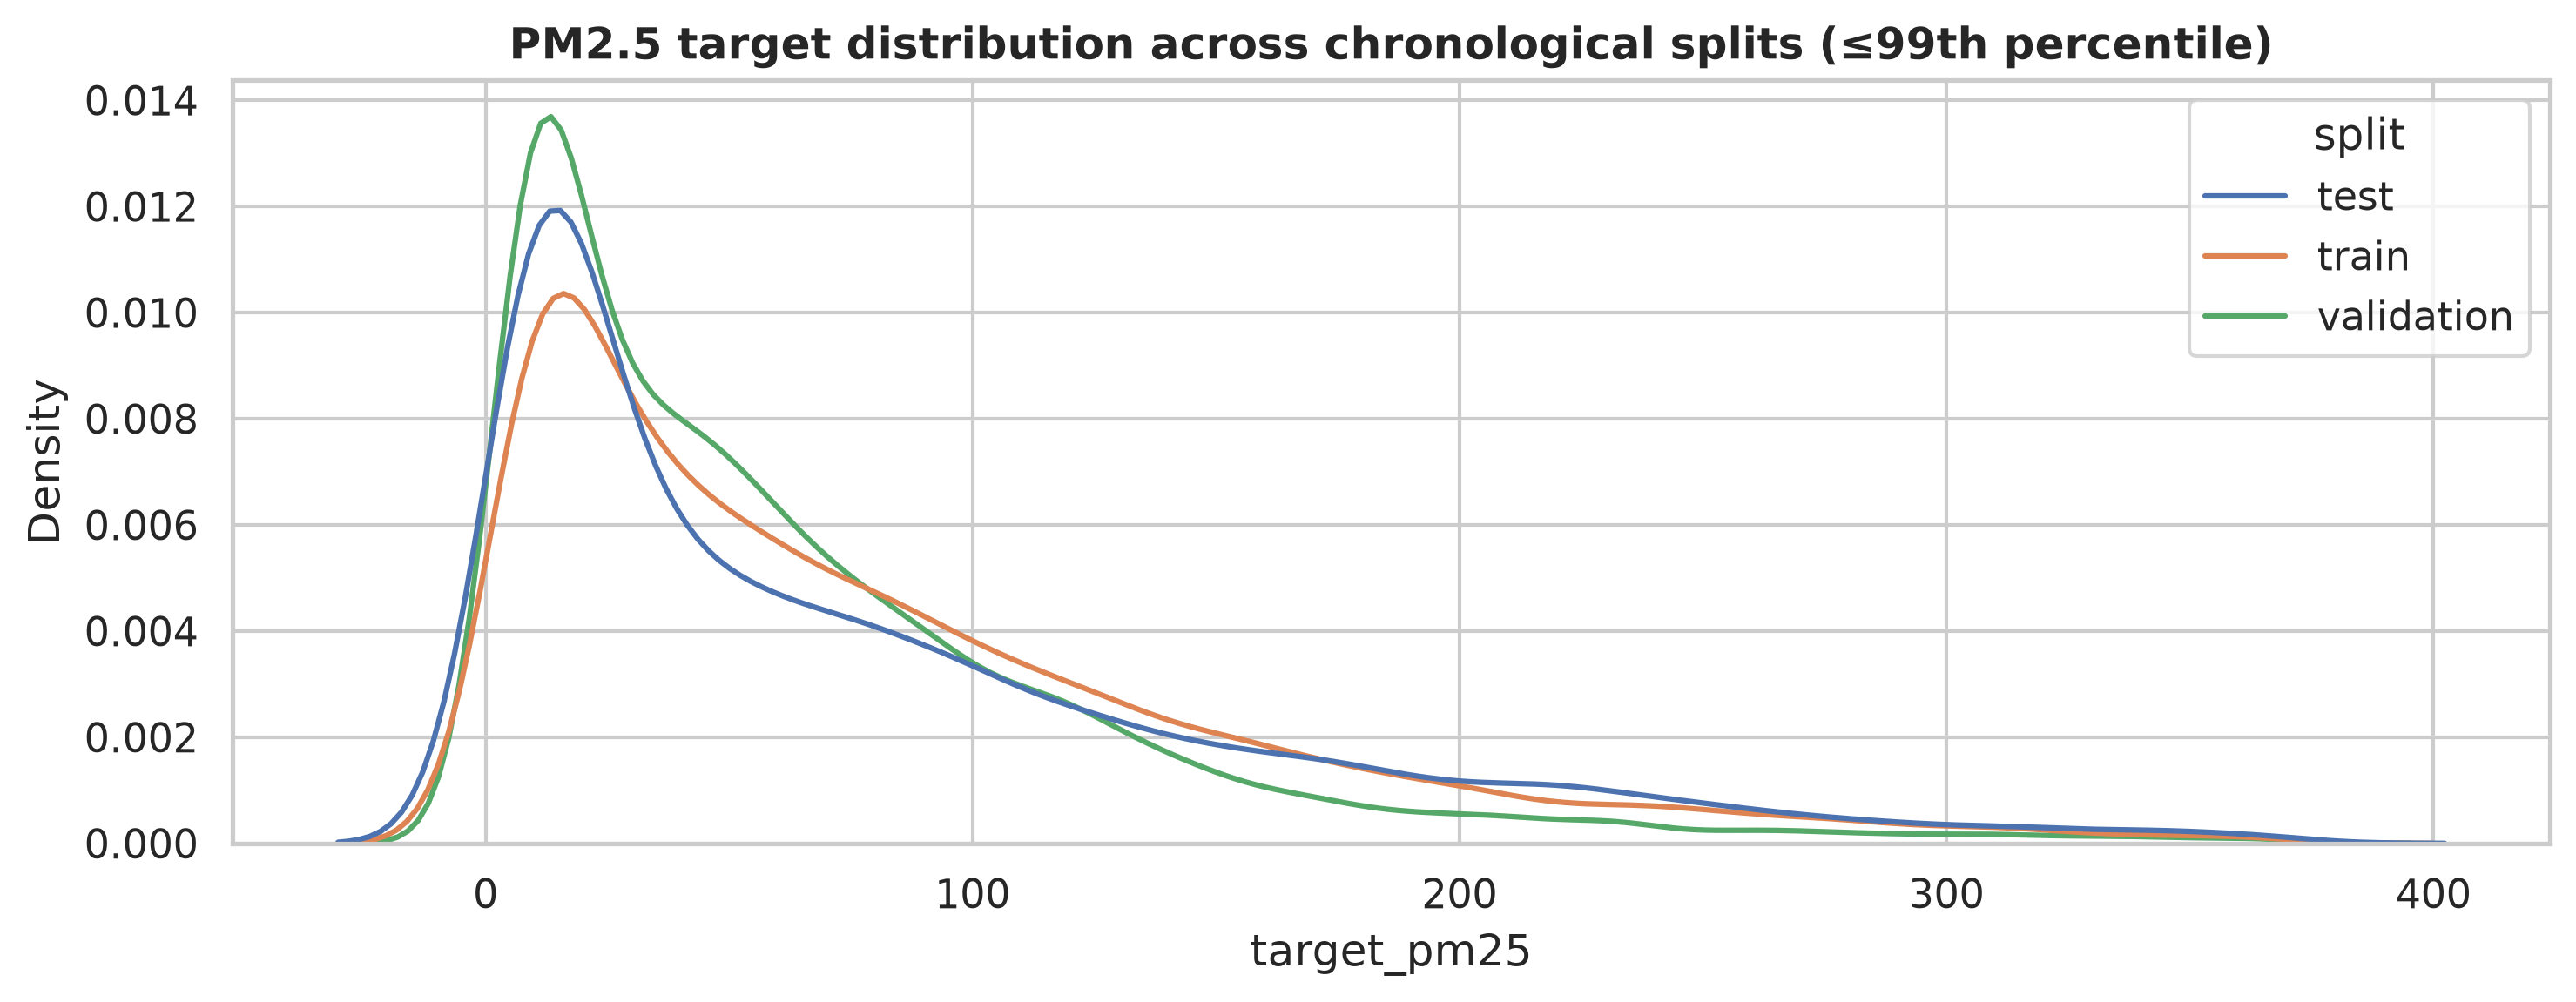

EDA and causal preprocessing complete.


In [6]:
feature_metadata = json.loads(PATHS.feature_metadata.read_text(encoding="utf-8"))
split_metadata = json.loads(PATHS.split_metadata.read_text(encoding="utf-8"))
split_distribution = pd.read_csv(
    PATHS.assignment1_tables / "target_distribution_by_split.csv", index_col=0
)
suffix = OPTIONS.artifact_suffix
fill_ablation = pd.read_csv(
    PATHS.assignment2_tables / f"forward_fill_ablation_summary{suffix}.csv"
)
lookback_ablation = pd.read_csv(
    PATHS.assignment2_tables / f"lookback_ablation_summary{suffix}.csv"
)
display(feature_metadata)
display(split_metadata)
display(split_distribution)
display(fill_ablation)
display(lookback_ablation)
display(Image(filename=str(
    PATHS.assignment1_figures / "target_distribution_by_split.png"
)))
print("EDA and causal preprocessing complete.")
